In [9]:
import pandas as pd
import numpy as np

In [10]:
pd.set_option("display.max_columns", None)
df = pd.read_csv("../data/raw/train.csv")

df.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [11]:
print("Shape:", df.shape)

df.info()

Shape: (913000, 4)
<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   date    913000 non-null  str  
 1   store   913000 non-null  int64
 2   item    913000 non-null  int64
 3   sales   913000 non-null  int64
dtypes: int64(3), str(1)
memory usage: 36.6 MB


In [12]:
(df.isnull().sum().to_frame("missing_count"))

,missing_count
date,0
store,0
item,0
sales,0


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.describe()

,store,item,sales
count,913000.000000,913000.000000,913000.000000
mean,5.500000,25.500000,52.250287
std,2.872283,14.430878,28.801144
min,1.000000,1.000000,0.000000
25%,3.000000,13.000000,30.000000
50%,5.500000,25.500000,47.000000
75%,8.000000,38.000000,70.000000
max,10.000000,50.000000,231.000000


In [15]:
df["date"] = pd.to_datetime(df["date"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    913000 non-null  datetime64[us]
 1   store   913000 non-null  int64         
 2   item    913000 non-null  int64         
 3   sales   913000 non-null  int64         
dtypes: datetime64[us](1), int64(3)
memory usage: 27.9 MB


In [16]:
print("Start", df["date"].min())
print("End", df["date"].max())

Start 2013-01-01 00:00:00
End 2017-12-31 00:00:00


In [17]:
df["store"].unique()


array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

In [18]:
df["item"].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50])

In [19]:
df.groupby(
    ["store",'item']
).ngroups

500

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

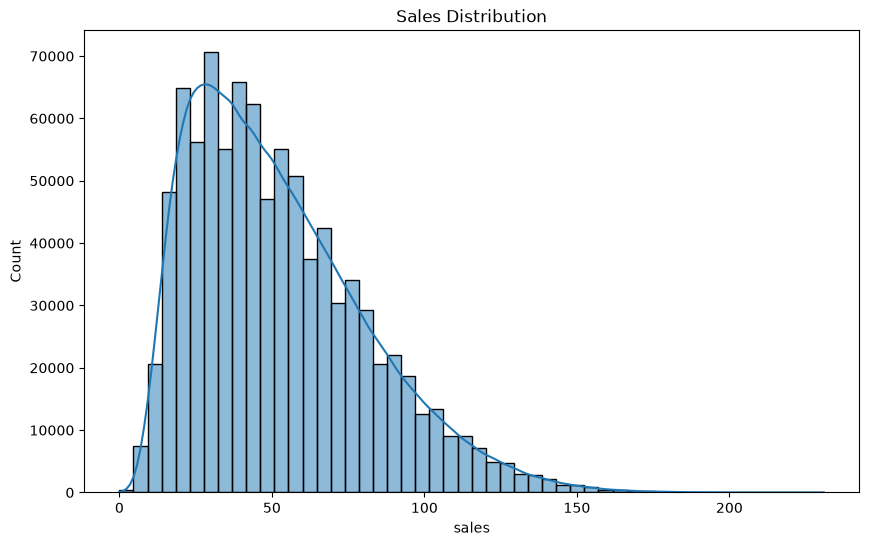

In [21]:
plt.figure(figsize=(10,6))

sns.histplot(
    df["sales"],
    bins=50,
    kde=True
)

plt.title("Sales Distribution")
plt.show()

In [22]:
daily_sales = (
    df.groupby("date")["sales"]
    .sum()
    .reset_index()
)

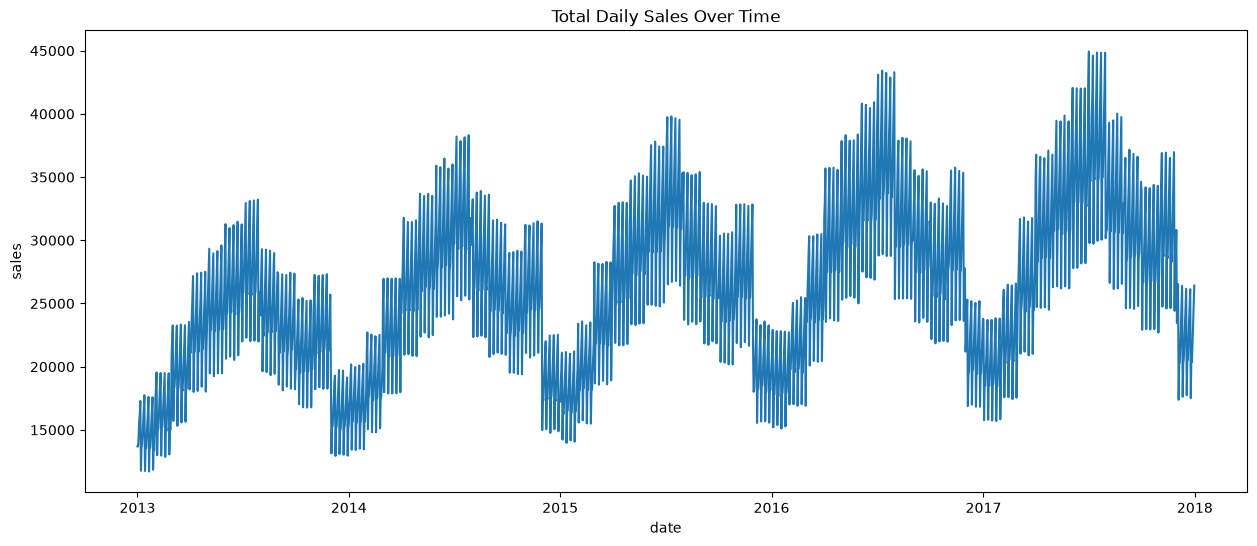

In [23]:
plt.figure(figsize=(15,6))

sns.lineplot(
    data=daily_sales,
    x="date",
    y="sales"
)

plt.title("Total Daily Sales Over Time")
plt.show()

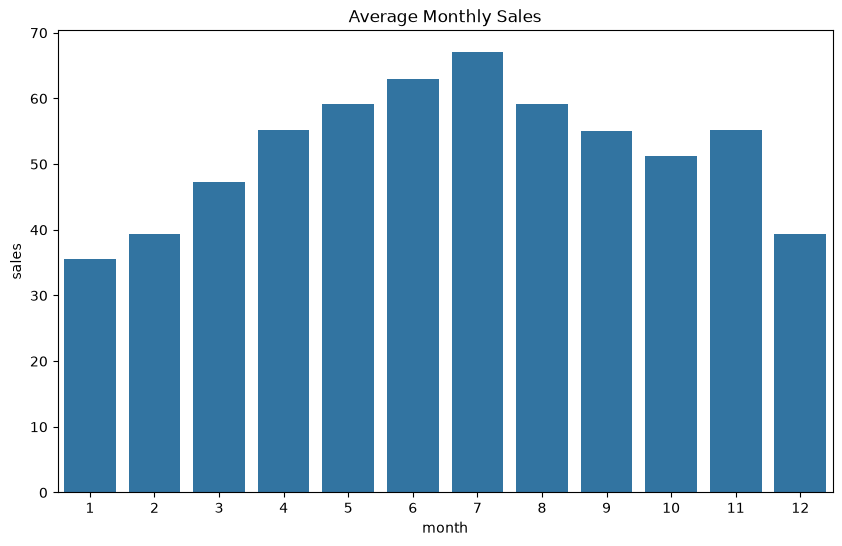

In [24]:
df["month"] = df["date"].dt.month
monthly_sales = (
    df.groupby("month")["sales"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=monthly_sales,
    x="month",
    y="sales"
)

plt.title("Average Monthly Sales")

plt.show()

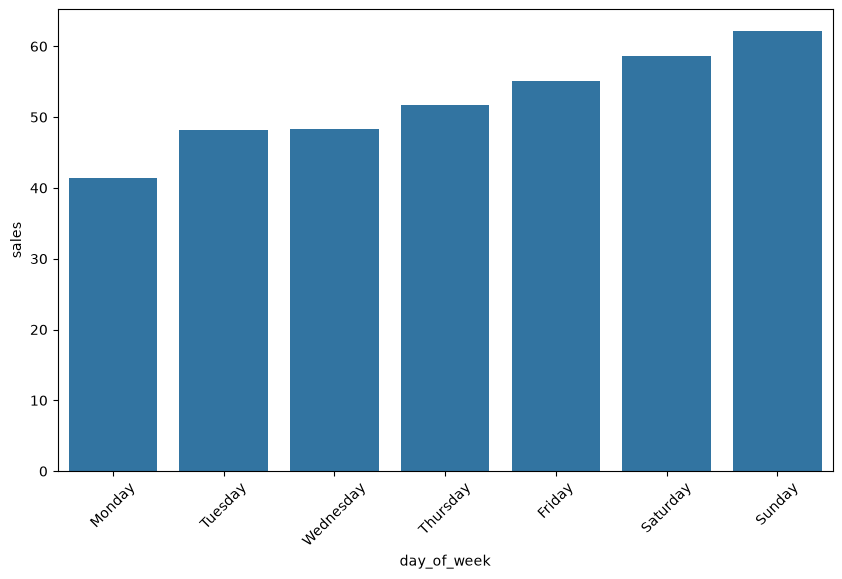

In [25]:
df["day_of_week"] = df["date"].dt.day_name()

dow_sales = (
    df.groupby("day_of_week")["sales"]
    .mean()
    .reset_index()
)

order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

dow_sales["day_of_week"] = pd.Categorical(
    dow_sales["day_of_week"],
    categories=order,
    ordered=True,
)

dow_sales = dow_sales.sort_values(
    "day_of_week"
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=dow_sales,
    x="day_of_week",
    y="sales"
)

plt.xticks(rotation=45)
plt.show()

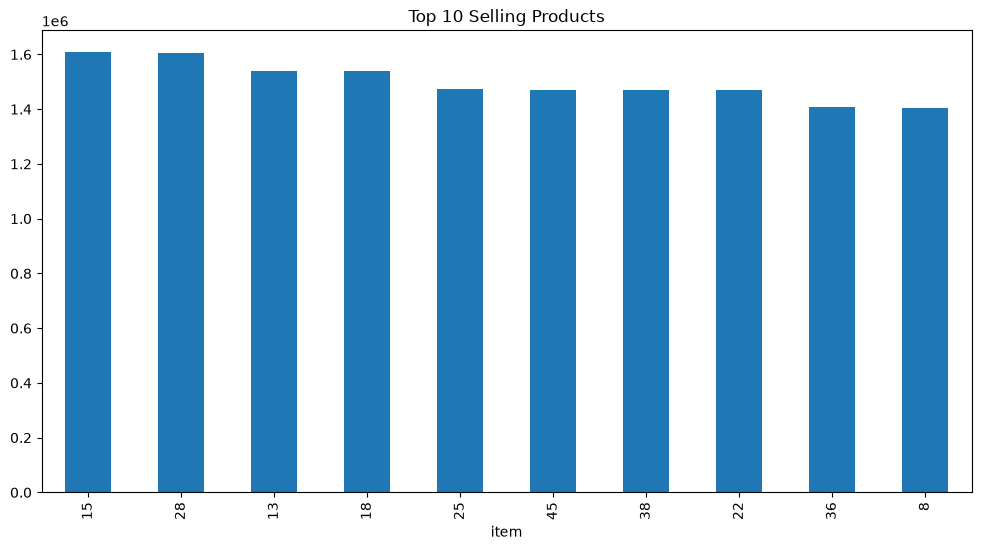

In [26]:
top_items = (
    df.groupby("item")["sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_items.plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Top 10 Selling Products")
plt.show()

In [27]:
top_stores = (
    df.groupby("store")["sales"]
    .sum()
    .sort_values(ascending=False)
)

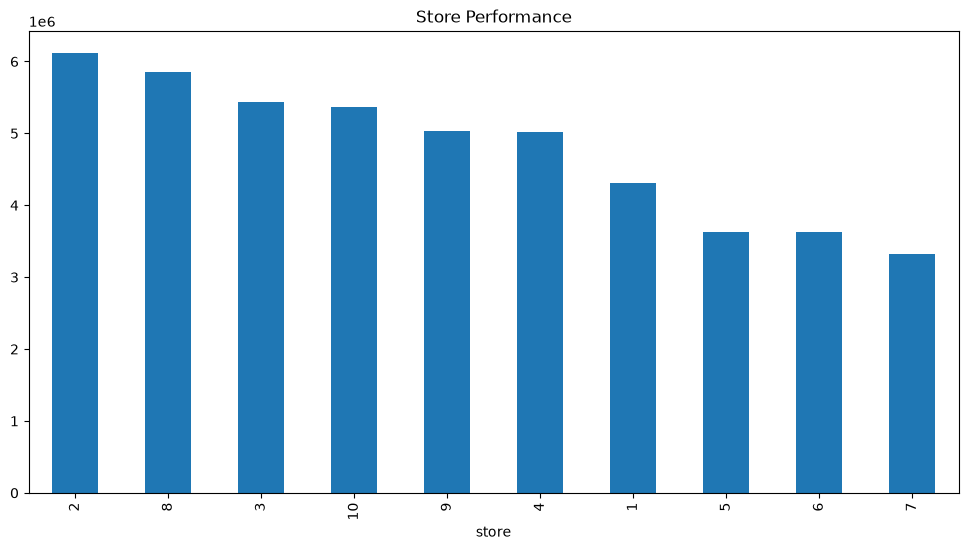

In [28]:
top_stores.plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Store Performance")
plt.show()

In [33]:
from pathlib import Path
import sys

project_root = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src" / "inventory_demand_forecasting").is_dir()
)
sys.path.insert(0, str(project_root))

from src.inventory_demand_forecasting.preprocess import (
    load_data,
    basic_data_quality_check,
)

df = load_data("../data/raw/train.csv")
basic_data_quality_check(df)

df = load_data("../data/raw/train.csv")

basic_data_quality_check(df)

{'rows': 913000, 'columns': 4, 'missing_values': 0, 'duplicate_rows': 0}

## Key Findings

1. Dataset contains X years of sales history.
2. No missing values detected.
3. No duplicate rows detected.
4. Strong weekly seasonality observed.
5. Certain products consistently outperform others.
6. Store sales vary across locations.
7. Historical behavior suggests demand forecasting is feasible.

## Next Step

Create time-series features:
- Year
- Month
- Week
- Day of week
- Lag 7
- Lag 14
- Lag 30
- Rolling averages